# 01 · Building overview (all floors, cleaned data)

The common EDA every floor notebook was repeating, done once on the shared cleaned data so the numbers
agree. Per-floor deep dives stay in `eda/floor*_<owner>.ipynb`.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="obj.round has no effect")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# `pip install -e .` from the repo root makes `sbanalytics` importable; this fallback works without it.
try:
    import sbanalytics
except ImportError:
    import sys
    from pathlib import Path
    sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "sbanalytics").is_dir()) / "src"))

from sbanalytics import data as D, registry as R, viz
viz.setup()
pd.set_option("display.precision", 2)
pd.set_option("display.width", 160)
from sbanalytics import baseline as B, kpis as K, config as C

In [2]:
h = D.load_hourly(None)
fh = B.floor_hourly(h)
fd = B.floor_daily(fh)
print(f"{len(h):,} zone-hours, {fh.floor.nunique()} floors, {fh.ts.min():%Y-%m-%d} to {fh.ts.max():%Y-%m-%d}")

434,808 zone-hours, 7 floors, 2018-07-01 to 2019-12-31


## 1 · Where the energy goes

End-use split per floor over the whole record (usable hours only).

,ac MWh,light MWh,plug MWh
floor,,,
1,435.5,722.5,239.5
2,282.1,56.8,20.8
3,162.2,69.9,16.5
4,179.8,56.4,27.7
5,178.0,71.6,21.6
6,146.7,82.7,19.1
7,293.0,72.7,9.0


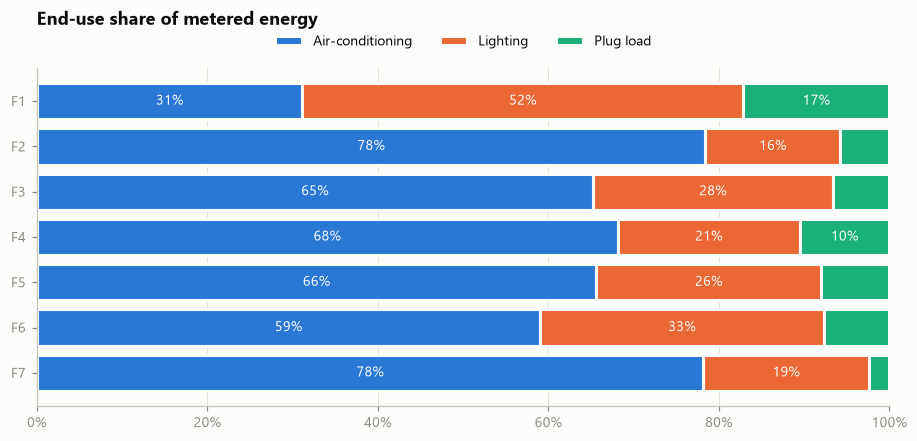

In [3]:
eu = fh[fh.ok].groupby("floor")[["ac_kwh", "light_kwh", "plug_kwh"]].sum()
share = eu.div(eu.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(10, 4))
left = np.zeros(len(share))
for col, key in zip(share.columns, ("ac", "light", "plug")):
    ax.barh([f"F{f}" for f in share.index], share[col], left=left, color=viz.END_USE_COLORS[key],
            label=viz.END_USE_LABELS[key], edgecolor=viz.SURFACE, linewidth=2)
    for i, (l, v) in enumerate(zip(left, share[col])):
        if v > 0.08:
            ax.text(l + v / 2, i, f"{v:.0%}", ha="center", va="center", color="white", fontsize=9)
    left += share[col].to_numpy()
ax.invert_yaxis(); ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.legend(ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.02)); ax.grid(axis="y", visible=False)
ax.set_title("End-use share of metered energy", pad=28)
viz.save(fig, "01_end_use_share")
(eu / 1000).round(1).rename(columns=lambda c: c.replace("_kwh", " MWh"))

AC is the largest end use on every floor except F1, where lighting dominates — consistent with F1 not being an office floor (eda/00 §5).

## 2 · Daily energy over time

Daily total per floor (usable days only). Gaps are outages, not zero use.

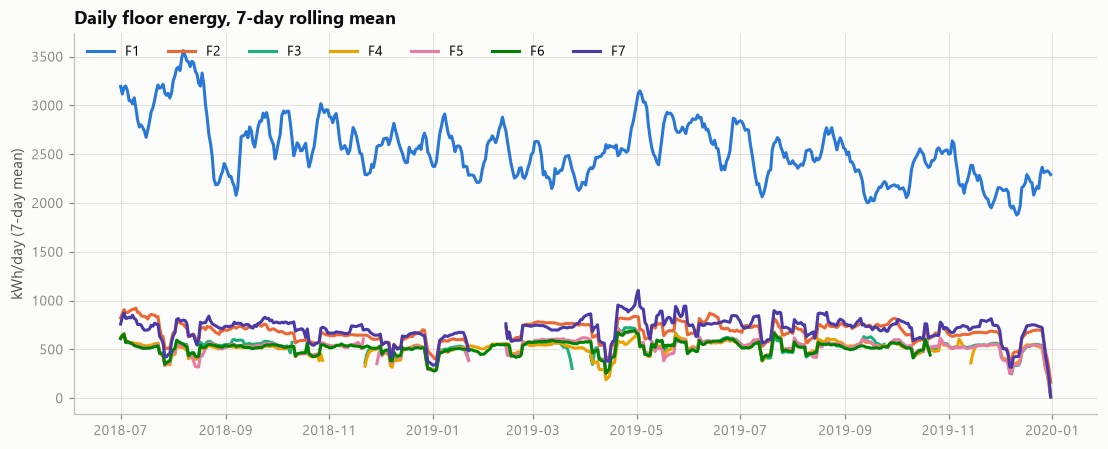

In [4]:
fig, ax = plt.subplots(figsize=(12, 4.5))
for f, g in fd.groupby("floor"):
    g = g.set_index("day")
    s = g.total_kwh.where(g.ok)
    ax.plot(s.index, s.rolling(7, min_periods=4, center=True).mean(), color=viz.FLOOR_COLORS[f], label=f"F{f}")
ax.set_ylabel("kWh/day (7-day mean)"); ax.set_title("Daily floor energy, 7-day rolling mean")
ax.legend(ncol=7, loc="upper left")
viz.save(fig, "01_daily_energy")

## 3 · Typical day by day type

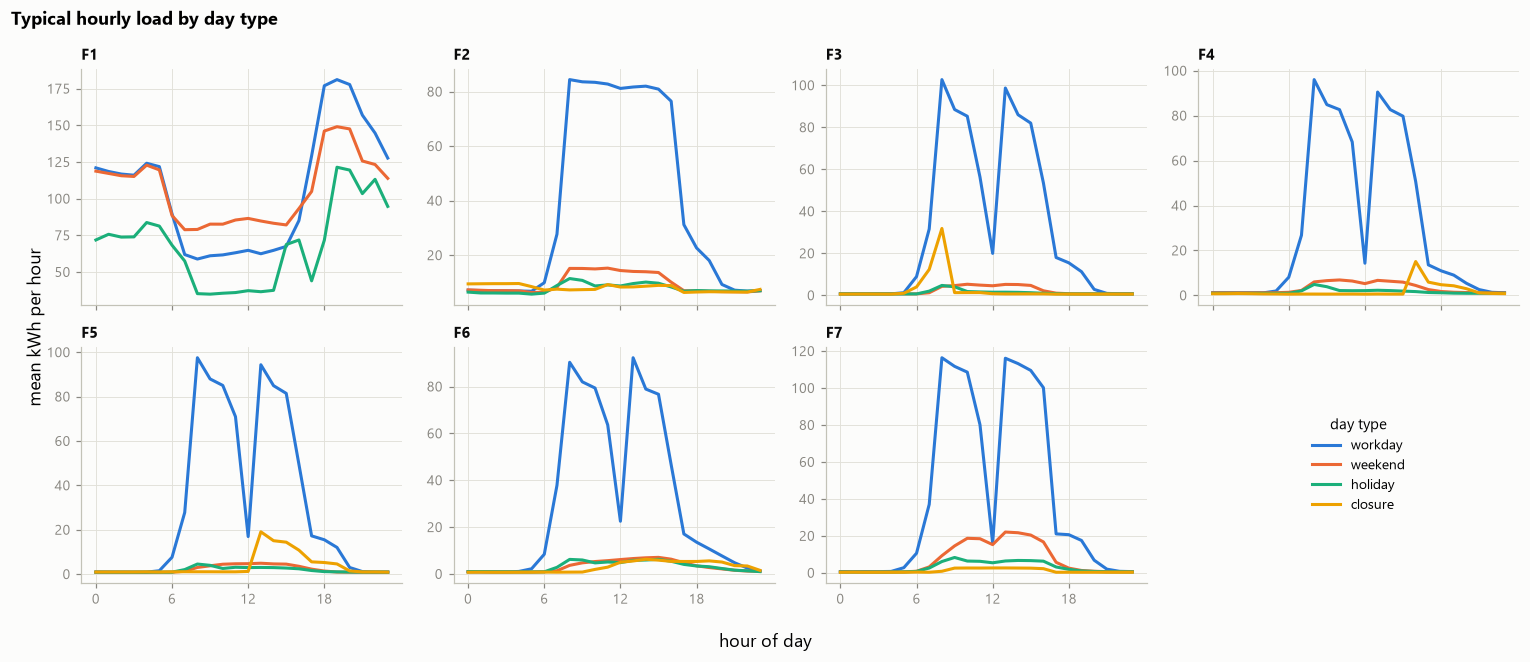

In [5]:
types = ["workday", "weekend", "holiday", "closure"]
prof = fh[fh.ok].groupby(["floor", "day_type", "hour"]).total_kwh.mean()
fig, axes = plt.subplots(2, 4, figsize=(14, 6), sharex=True)
for ax, f in zip(axes.flat, C.FLOORS):
    for i, t in enumerate(types):
        if (f, t) in prof.index:
            p = prof.loc[(f, t)]
            ax.plot(p.index, p, color=viz.CATEGORICAL[i], label=t)
    ax.set_title(f"F{f}", fontsize=10); ax.set_xticks(range(0, 24, 6))
axes.flat[-1].axis("off")
handles = [plt.Line2D([], [], color=viz.CATEGORICAL[i], lw=2, label=t) for i, t in enumerate(types)]
axes.flat[-1].legend(handles=handles, loc="center", title="day type")
fig.supylabel("mean kWh per hour"); fig.supxlabel("hour of day")
fig.suptitle("Typical hourly load by day type", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
viz.save(fig, "01_profiles_by_day_type")

In [6]:
dt = D.load_day_types()
dt.pivot_table(index="floor", columns="day_type", values="date", aggfunc="count", fill_value=0)

day_type,closure,holiday,holiday_worked,weekend,workday
floor,,,,,
1,0,1,36,147,365
2,4,36,1,147,361
3,3,36,1,147,362
4,7,36,1,147,358
5,5,36,1,147,360
6,1,36,1,147,364
7,2,36,1,147,363


Closures are workdays on which a floor used < 30% of a typical workday's 08:00–16:59 energy; worked holidays are listed holidays at ≥ 70%. Treating these correctly stops them being reported later as anomalies.

## 4 · Carpet plot (one floor)

Every hour of the record as a pixel: schedules, lunch shutdowns, weekends and outages all show up. Change `FLOOR` to view another floor.

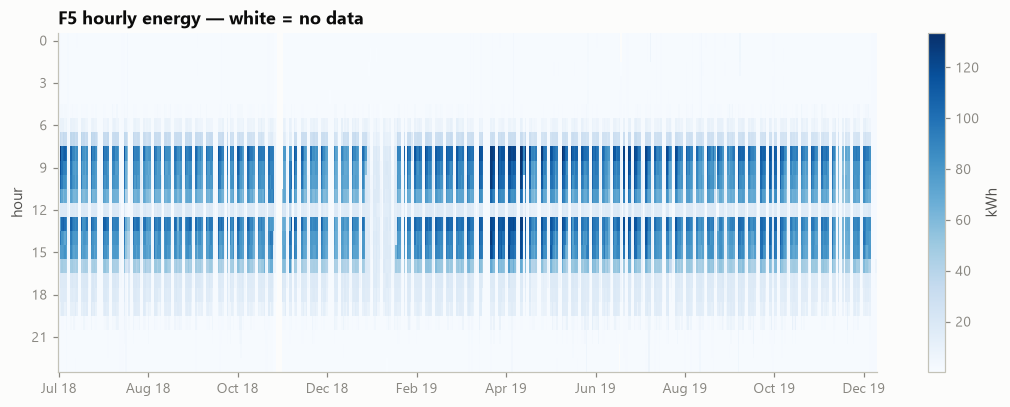

In [7]:
FLOOR = 5
g = fh[fh.floor == FLOOR]
carpet = g.pivot_table(index=g.ts.dt.normalize(), columns="hour", values="total_kwh", dropna=False)
fig, ax = plt.subplots(figsize=(12, 4))
im = ax.imshow(carpet.T.to_numpy(), aspect="auto", cmap=viz.SEQUENTIAL, interpolation="nearest")
ax.set_yticks(range(0, 24, 3)); ax.set_ylabel("hour")
ticks = np.arange(0, len(carpet), 60)
ax.set_xticks(ticks, [carpet.index[i].strftime("%b %y") for i in ticks]); ax.grid(False)
fig.colorbar(im, ax=ax, label="kWh")
ax.set_title(f"F{FLOOR} hourly energy — white = no data")
viz.save(fig, f"01_carpet_f{FLOOR}")

## 5 · Comfort in occupied, cooled hours

Workday hours inside each floor's AC schedule, AC running, sensor valid (≥ 30 min of readings). Only zones whose sensor represents room air (F5 z1 is a supply-air sensor and is excluded). F1 has no sensors. Band: 23–26 °C (`registry.CONVENTIONS`).

In [8]:
comfort = K.zone_comfort(h)
C.TABLES.mkdir(parents=True, exist_ok=True)
comfort.to_csv(C.TABLES / "zone_comfort.csv", index=False)
comfort.round(2)

,floor,zone,hours,mean_temp_c,share_below_lo,share_above_hi,cold_degree_hours,share_rh_above,ac_kwh_in_window
0,2,z1,2133,21.48,0.77,0.00,3593.74,0.45,62536.44
1,2,z2,2206,22.10,0.78,0.08,3210.41,0.94,63057.87
2,2,z4,1748,18.55,1.00,0.00,7784.48,0.99,14899.05
3,3,z1,1791,22.73,0.67,0.01,1261.73,0.19,37945.49
4,3,z2,1875,22.29,0.68,0.00,1805.45,0.12,30518.90
5,3,z4,1876,19.47,0.97,0.00,6660.10,0.92,33222.26
6,3,z5,1582,20.23,0.98,0.00,4401.31,0.96,12539.88
7,4,z1,1923,21.67,0.79,0.00,2982.89,0.72,41599.47
8,4,z2,1888,21.10,0.80,0.00,3869.17,1.00,28573.18
9,4,z4,1584,20.07,0.92,0.01,4830.50,0.53,30657.30


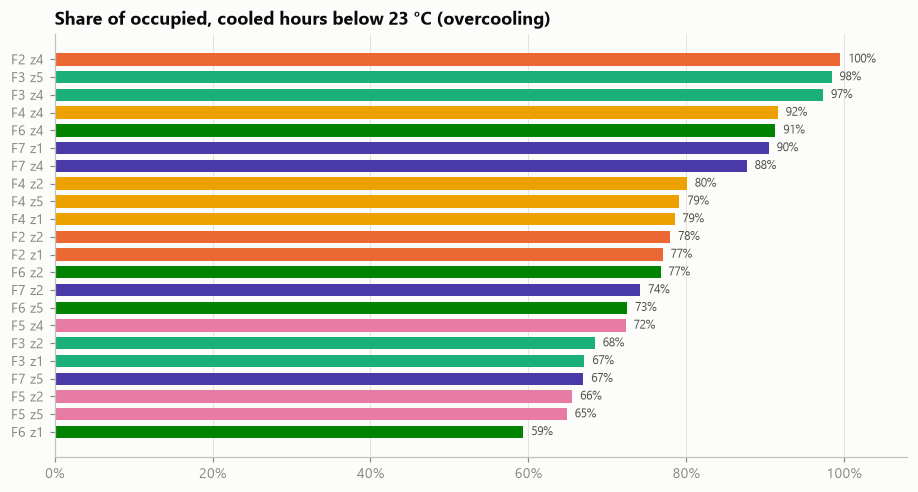

In [9]:
c = comfort.sort_values("share_below_lo")
fig, ax = plt.subplots(figsize=(10, 5))
labels = [f"F{f} {z}" for f, z in zip(c.floor, c.zone)]
ax.barh(labels, c.share_below_lo, color=[viz.FLOOR_COLORS[f] for f in c.floor], height=0.7)
for i, v in enumerate(c.share_below_lo):
    ax.text(v + 0.01, i, f"{v:.0%}", va="center", fontsize=8, color=viz.INK_2)
ax.set_xlim(0, 1.08); ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}"); ax.grid(axis="y", visible=False)
ax.set_title("Share of occupied, cooled hours below 23 °C (overcooling)")
viz.save(fig, "01_overcooling_by_zone")